In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

import torchvision.transforms as T
import torchvision.transforms.functional as TF
from PIL import Image

from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
import seaborn as sns
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
class CVCColonDBDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None, mask_transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.mask_transform = mask_transform

        all_images = sorted(os.listdir(img_dir))
        mask_stems = {
            os.path.splitext(m)[0] for m in os.listdir(mask_dir)
        }
        self.images = [
            f for f in all_images
            if os.path.splitext(f)[0] in mask_stems
        ]

    def get_base_name(self, filename):
        return os.path.splitext(filename)[0]

    def get_class(self, filename):
        return 1

    def load_mask(self, base_name):
        for ext in (".jpg", ".jpeg", ".png", ".bmp"):
            mask_path = os.path.join(self.mask_dir, base_name + ext)
            if os.path.exists(mask_path):
                mask = np.array(Image.open(mask_path).convert("L"))
                mask = (mask > 127).astype(np.uint8)
                return Image.fromarray(mask * 255)

        raise FileNotFoundError(
            f"No mask found for '{base_name}' in '{self.mask_dir}'"
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)
        base_name = self.get_base_name(img_name)

        image = Image.open(img_path).convert("RGB")
        mask_pil = self.load_mask(base_name)

        if self.transform:
            image = self.transform(image)

        if self.mask_transform:
            mask = self.mask_transform(mask_pil)
            mask = (mask > 0.5).long().squeeze(0)
        else:
            mask = torch.tensor(
                (np.array(mask_pil) > 127).astype(np.uint8),
                dtype=torch.long
            )

        label = torch.tensor(self.get_class(img_name), dtype=torch.long)

        return image, mask, label

In [3]:
dataset = CVCColonDBDataset(
    "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/images",
    "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/masks"
)

img, mask, label = dataset[0]

print(torch.unique(mask))
print(torch.unique(label))

tensor([0, 1])
tensor([1])


In [4]:
from collections import Counter

class_counter = Counter()
total_masks = 0
missing_masks = 0
missing_images_list = []

for i in range(len(dataset)):
    img_name = dataset.images[i]
    img, mask, label = dataset[i]

    if label.item() == 1:
        class_counter["polyp"] += 1
    else:
        class_counter["unknown"] += 1

    if mask.sum().item() > 0:
        total_masks += 1
    else:
        missing_masks += 1
        missing_images_list.append(img_name)

    if (i + 1) % 100 == 0:
        print(f"  Processed {i + 1}/{len(dataset)} images...")

print("\n===== DATASET SUMMARY =====")
print("Total images         :", len(dataset))
print("Total classes        :", len(class_counter))
print("Class distribution   :", dict(class_counter))
print("Images with masks    :", total_masks)
print("Images without masks :", missing_masks)

if missing_images_list:
    print("\n===== IMAGES WITHOUT / EMPTY MASKS =====")
    for name in missing_images_list:
        print(" ", name)
else:
    print("\n✓ All images have valid non-empty masks.")

  Processed 100/380 images...
  Processed 200/380 images...
  Processed 300/380 images...

===== DATASET SUMMARY =====
Total images         : 380
Total classes        : 1
Class distribution   : {'polyp': 380}
Images with masks    : 380
Images without masks : 0

✓ All images have valid non-empty masks.


In [5]:
import torch

labels_all = []

for i in range(len(dataset)):
    _, _, label = dataset[i]
    labels_all.append(label.item())

labels_all = torch.tensor(labels_all)

print("Unique classes in dataset:", torch.unique(labels_all))

Unique classes in dataset: tensor([1])


In [6]:
import numpy as np

def perfect_split(dataset, train_ratio=0.8, val_ratio=0.10, test_ratio=0.10, random_state=42):
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6

    indices = np.arange(len(dataset))

    rng = np.random.default_rng(random_state)
    shuffled = rng.permutation(indices)

    n_train = int(len(shuffled) * train_ratio)
    n_val   = int(len(shuffled) * val_ratio)

    train_idx = shuffled[:n_train]
    val_idx   = shuffled[n_train : n_train + n_val]
    test_idx  = shuffled[n_train + n_val:]

    return {
        'train': train_idx.tolist(),
        'val':   val_idx.tolist(),
        'test':  test_idx.tolist()
    }

splits = perfect_split(dataset)

print(f"Total images : {len(dataset)}")
print(f"Train set    : {len(splits['train'])} images")
print(f"Val set      : {len(splits['val'])} images")
print(f"Test set     : {len(splits['test'])} images")

assert len(set(splits['train']) & set(splits['val']))  == 0, "Train/Val overlap!"
assert len(set(splits['train']) & set(splits['test'])) == 0, "Train/Test overlap!"
assert len(set(splits['val'])   & set(splits['test'])) == 0, "Val/Test overlap!"
print("\n✓ No overlap between splits.")

Total images : 380
Train set    : 304 images
Val set      : 38 images
Test set     : 38 images

✓ No overlap between splits.


In [7]:
from collections import defaultdict

classes = ['polyp']

for split_name, indices in splits.items():
    class_counts = defaultdict(int)
    for idx in indices:
        _, _, label = dataset[idx]
        class_name = classes[label.item() - 1]
        class_counts[class_name] += 1

    print(f"\n{split_name.capitalize()} set class counts:")
    for i, cls_name in enumerate(classes):
        print(f"  Class {i + 1} : {cls_name} - {class_counts[cls_name]} images")


Train set class counts:
  Class 1 : polyp - 304 images

Val set class counts:
  Class 1 : polyp - 38 images

Test set class counts:
  Class 1 : polyp - 38 images


In [8]:
import random
import numpy as np
import torch
from torch.utils.data import Dataset
from PIL import Image
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import torch.nn.functional as F

image_transform = T.Compose([
    T.Resize((352, 352)),                     # FIXED (was 325, 352)
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225])
])

def mask_transform(mask):
    mask = mask.unsqueeze(0).unsqueeze(0).float()
    mask = F.interpolate(mask, size=(352, 352), mode='nearest')
    mask = mask.squeeze().long()
    return mask

def augment(img, mask):
    if random.random() > 0.5:
        img  = TF.hflip(img)
        mask = torch.flip(mask, dims=[1])

    if random.random() > 0.5:
        img  = TF.vflip(img)
        mask = torch.flip(mask, dims=[0])

    angle = random.uniform(-20, 20)
    img  = TF.rotate(img, angle)
    mask = TF.rotate(
        mask.unsqueeze(0), angle,
        interpolation=TF.InterpolationMode.NEAREST
    ).squeeze(0)

    if random.random() > 0.5:
        i, j, h, w = T.RandomResizedCrop.get_params(
            img, scale=(0.75, 1.0), ratio=(0.9, 1.1)
        )
        img  = TF.resized_crop(img,  i, j, h, w, size=(352, 352))     # FIXED (was 256)
        mask = TF.resized_crop(
            mask.unsqueeze(0), i, j, h, w,
            size=(352, 352),                                          # FIXED (was 256)
            interpolation=TF.InterpolationMode.NEAREST
        ).squeeze(0)

    return img, mask

class TransformedDataset(Dataset):
    def __init__(self, base_dataset, image_transform=None,
                 mask_transform=None, augment=False):
        self.base_dataset     = base_dataset
        self.image_transform  = image_transform
        self.mask_transform   = mask_transform
        self.do_augment       = augment

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, mask, label = self.base_dataset[idx]

        if self.do_augment:
            img, mask = augment(img, mask)

        if self.image_transform:
            img = self.image_transform(img)

        if self.mask_transform:
            mask = self.mask_transform(mask)

        if self.do_augment:
            if random.random() > 0.5:
                img = img + random.uniform(-0.15, 0.15)

            if random.random() > 0.5:
                img = img * random.uniform(0.8, 1.2)

            if random.random() > 0.5:
                shift = torch.randn(3, 1, 1) * 0.05
                img   = img + shift

            if random.random() > 0.5:
                img = img + torch.randn_like(img) * 0.02

            img = torch.clamp(img, -2.5, 2.5)

        return img, mask, label


from torch.utils.data import Subset

train_dataset = Subset(dataset, splits['train'])
val_dataset   = Subset(dataset, splits['val'])
test_dataset  = Subset(dataset, splits['test'])

train_dataset = TransformedDataset(train_dataset, image_transform=image_transform,
                                   mask_transform=mask_transform, augment=False)
val_dataset   = TransformedDataset(val_dataset, image_transform=image_transform,
                                   mask_transform=mask_transform, augment=False)
test_dataset  = TransformedDataset(test_dataset, image_transform=image_transform,
                                   mask_transform=mask_transform, augment=False)

In [9]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=8, shuffle=False)

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)

        intersection = (probs * targets).sum(dim=(2,3))
        union = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3))

        dice = (2 * intersection + self.smooth) / (union + self.smooth)
        return 1 - dice.mean()


class CombinedLoss(nn.Module):
    def __init__(self, dice_weight=0.6, bce_weight=0.4):
        super().__init__()
        self.dice = DiceLoss()
        self.bce  = nn.BCEWithLogitsLoss()
        self.dw   = dice_weight
        self.bw   = bce_weight

    def forward(self, logits, targets):
        targets = targets.unsqueeze(1).float()
        return self.dw * self.dice(logits, targets) + \
               self.bw * self.bce(logits, targets)


def dice_score(logits, targets, smooth=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > 0.4).float()

    targets = targets.unsqueeze(1).float()

    intersection = (preds * targets).sum(dim=(2,3))
    union = preds.sum(dim=(2,3)) + targets.sum(dim=(2,3))

    dice = (2 * intersection + smooth) / (union + smooth)
    return dice.mean()


def iou_score(logits, targets, smooth=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > 0.4).float()

    targets = targets.unsqueeze(1).float()

    intersection = (preds * targets).sum(dim=(2,3))
    union = preds.sum(dim=(2,3)) + targets.sum(dim=(2,3)) - intersection

    iou = (intersection + smooth) / (union + smooth)
    return iou.mean()

# DeepLabV3+

In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision


class ConvBNReLU(nn.Sequential):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1, dilation=1):
        super().__init__(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride, padding=padding, dilation=dilation, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )


def _load_resnet34(pretrained=True):
    weights = torchvision.models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None
    # No try/except: if the download fails, it raises instead of silently training from scratch.
    r = torchvision.models.resnet34(weights=weights)
    if pretrained:
        print("ResNet34: ImageNet weights loaded")

    # torchvision's BasicBlock can't be dilated through replace_stride_with_dilation,
    # so make layer4 output stride 16 by hand: remove the stride and dilate every 3x3 conv by 2.
    for m in r.layer4.modules():
        if isinstance(m, nn.Conv2d):
            m.stride = (1, 1)
            if m.kernel_size == (3, 3):
                m.dilation = (2, 2)
                m.padding = (2, 2)
    return r


class ResNet34Encoder(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        r = _load_resnet34(pretrained)
        self.conv1, self.bn1, self.relu, self.maxpool = r.conv1, r.bn1, r.relu, r.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        low_level = self.layer1(x)          # stride 4, 64 channels
        x = self.layer2(low_level)
        x = self.layer3(x)
        high_level = self.layer4(x)         # stride 16, 512 channels
        return low_level, high_level


class ASPP(nn.Module):
    def __init__(self, in_channels=512, out_channels=256, atrous_rates=(6, 12, 18)):
        super().__init__()
        self.branch1 = ConvBNReLU(in_channels, out_channels, kernel_size=1, padding=0)
        self.atrous_branches = nn.ModuleList([
            ConvBNReLU(in_channels, out_channels, kernel_size=3, padding=r, dilation=r)
            for r in atrous_rates
        ])
        self.global_pool = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, out_channels, 1, bias=False),
            nn.ReLU(inplace=True)
        )
        self.project = nn.Sequential(
            nn.Conv2d(out_channels * (2 + len(atrous_rates)), out_channels, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1)
        )

    def forward(self, x):
        size = x.shape[2:]
        features = [self.branch1(x)]
        features.extend(branch(x) for branch in self.atrous_branches)
        pooled = F.interpolate(self.global_pool(x), size=size, mode='bilinear', align_corners=False)
        features.append(pooled)
        return self.project(torch.cat(features, dim=1))


class DeepLabV3PlusDecoder(nn.Module):
    def __init__(self, low_channels=64, aspp_channels=256, low_proj_channels=48, decoder_channels=256):
        super().__init__()
        self.low_projection = ConvBNReLU(low_channels, low_proj_channels, kernel_size=1, padding=0)
        self.decoder = nn.Sequential(
            ConvBNReLU(aspp_channels + low_proj_channels, decoder_channels),
            ConvBNReLU(decoder_channels, decoder_channels),
            nn.Dropout(0.1)
        )

    def forward(self, high_level, low_level):
        high_level = F.interpolate(high_level, size=low_level.shape[2:], mode='bilinear', align_corners=False)
        low_level = self.low_projection(low_level)
        return self.decoder(torch.cat([high_level, low_level], dim=1))


class DeepLabV3Plus(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, pretrained=True, aspp_rates=(6, 12, 18)):
        super().__init__()
        if in_channels != 3:
            raise ValueError("The ResNet34 encoder requires 3-channel input.")

        self.encoder = ResNet34Encoder(pretrained=pretrained)
        self.aspp = ASPP(512, 256, aspp_rates)
        self.decoder = DeepLabV3PlusDecoder(64, 256, 48, 256)
        self.classifier = nn.Conv2d(256, out_channels, kernel_size=1)

    def forward(self, x):
        H, W = x.shape[2:]
        low_level, high_level = self.encoder(x)
        x = self.aspp(high_level)
        x = self.decoder(x, low_level)
        logits = self.classifier(x)
        return F.interpolate(logits, size=(H, W), mode='bilinear', align_corners=False)

    def param_groups(self, lr_enc=1e-4, lr_dec=3e-4):
        enc = list(self.encoder.parameters())
        dec = list(self.aspp.parameters()) + list(self.decoder.parameters()) + list(self.classifier.parameters())
        return [{'params': enc, 'lr': lr_enc}, {'params': dec, 'lr': lr_dec}]


model = DeepLabV3Plus(in_channels=3, out_channels=1, pretrained=True).to(device)

with torch.no_grad():
    y = model(torch.randn(2, 3, 352, 352, device=device))
print(y.shape)   # expect torch.Size([2, 1, 352, 352])

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total params: {total_params / 1e6:.2f}M | Trainable: {trainable_params / 1e6:.2f}M")
print(f"Encoder: {sum(p.numel() for p in model.encoder.parameters()) / 1e6:.2f}M | ASPP: {sum(p.numel() for p in model.aspp.parameters()) / 1e6:.2f}M | Decoder + classifier: {(sum(p.numel() for p in model.decoder.parameters()) + sum(p.numel() for p in model.classifier.parameters())) / 1e6:.2f}M")

ResNet34: ImageNet weights loaded
torch.Size([2, 1, 352, 352])
Total params: 26.71M | Trainable: 26.71M
Encoder: 21.28M | ASPP: 4.13M | Decoder + classifier: 1.29M


In [28]:
import time
import torch
import pandas as pd


def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable


@torch.no_grad()
def latency(m, x, warmup=20, runs=50):
    m.eval()

    for _ in range(warmup):
        _ = m(x)

    if x.is_cuda:
        torch.cuda.synchronize(x.device)

    start = time.perf_counter()

    for _ in range(runs):
        _ = m(x)

    if x.is_cuda:
        torch.cuda.synchronize(x.device)

    ms = (time.perf_counter() - start) / runs * 1000
    fps = 1000.0 / ms if ms > 0 else float("inf")

    return ms, fps


@torch.no_grad()
def flops(m, x):
    activities = [torch.profiler.ProfilerActivity.CPU]

    if x.is_cuda:
        activities.append(torch.profiler.ProfilerActivity.CUDA)

    m.eval()

    with torch.profiler.profile(
        activities=activities,
        with_flops=True
    ) as prof:
        _ = m(x)

    total_flops = sum(
        getattr(event, "flops", 0) or 0
        for event in prof.key_averages()
    )

    return total_flops / 1e9


@torch.no_grad()
def efficiency(name, m, x):
    m.eval()

    total_params, trainable_params = count_params(m)
    gflops = flops(m, x)
    latency_ms, fps = latency(m, x)

    gpu_memory = None

    if x.is_cuda:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(x.device)

        _ = m(x)
        torch.cuda.synchronize(x.device)

        gpu_memory = (
            torch.cuda.max_memory_allocated(x.device) / (1024 ** 2)
        )

    result = {
        "Model": name,
        "Params(M)": total_params / 1e6,
        "Trainable(M)": trainable_params / 1e6,
        "GFLOPs": gflops,
        "Latency(ms)": latency_ms,
        "FPS": fps,
        "GPU(MB)": gpu_memory
    }

    message = (
        f"{name}: "
        f"Params={total_params / 1e6:.3f}M | "
        f"Trainable={trainable_params / 1e6:.3f}M | "
        f"GFLOPs={gflops:.3f} | "
        f"Latency={latency_ms:.2f}ms | "
        f"FPS={fps:.2f}"
    )

    if gpu_memory is not None:
        message += f" | GPU={gpu_memory:.1f}MB"

    print(message)

    return result


# Model initialization: matches your DeepLabV3Plus implementation
model = DeepLabV3Plus(
    in_channels=3,
    out_channels=1,
    pretrained=True,
    aspp_rates=(6, 12, 18)
).to(device)

dummy = torch.randn(1, 3, 352, 352, device=device)

r1 = efficiency("DeepLabV3+", model, dummy)

print("\nParameter breakdown:")

for name, module in [
    ("Encoder", model.encoder),
    ("ASPP", model.aspp),
    ("Low-level projection", model.decoder.low_projection),
    ("Decoder", model.decoder.decoder),
    ("Classifier", model.classifier),
    ("Full model", model)
]:
    total, trainable = count_params(module)

    print(
        f"{name:<22}: "
        f"{total / 1e6:.3f}M total | "
        f"{trainable / 1e6:.3f}M trainable"
    )

efficiency_df = pd.DataFrame([r1])

print("\n", efficiency_df.to_string(index=False))

ResNet34: ImageNet weights loaded
DeepLabV3+: Params=26.711M | Trainable=26.711M | GFLOPs=51.513 | Latency=15.25ms | FPS=65.58 | GPU=799.2MB

Parameter breakdown:
Encoder               : 21.285M total | 21.285M trainable
ASPP                  : 4.131M total | 4.131M trainable
Low-level projection  : 0.003M total | 0.003M trainable
Decoder               : 1.291M total | 1.291M trainable
Classifier            : 0.000M total | 0.000M trainable
Full model            : 26.711M total | 26.711M trainable

      Model  Params(M)  Trainable(M)    GFLOPs  Latency(ms)       FPS    GPU(MB)
DeepLabV3+  26.710689     26.710689 51.512607    15.249473 65.576036 799.172363


In [29]:
import random, math, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


class StructureDiceLoss(nn.Module):
    def __init__(self, dice_w=0.5):
        super().__init__()
        self.dice_w = dice_w

    def forward(self, logits, targets):
        t = targets.unsqueeze(1).float()
        weit = 1 + 5 * torch.abs(F.avg_pool2d(t, 31, 1, 15) - t)
        wbce = (F.binary_cross_entropy_with_logits(logits, t, reduction='none') * weit).sum((2, 3)) / weit.sum((2, 3))
        p = torch.sigmoid(logits)
        inter = (p * t * weit).sum((2, 3))
        union = ((p + t) * weit).sum((2, 3))
        wiou = 1 - (inter + 1) / (union - inter + 1)
        inter_d = (p * t).sum((2, 3))
        den = p.sum((2, 3)) + t.sum((2, 3))
        dice = 1 - (2 * inter_d + 1e-6) / (den + 1e-6)
        return (wbce + wiou).mean() + self.dice_w * dice.mean()


criterion = StructureDiceLoss().to(device)

num_epochs = 150
optimizer = torch.optim.AdamW(
    model.param_groups(lr_enc=1e-4, lr_dec=3e-4),
    weight_decay=1e-4
)

warmup_epochs = 5

def lr_lambda(ep):
    if ep < warmup_epochs:
        return (ep + 1) / warmup_epochs
    prog = (ep - warmup_epochs) / max(1, num_epochs - warmup_epochs)
    return max(0.01, 0.5 * (1 + math.cos(math.pi * prog)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

ema = copy.deepcopy(model).to(device)
ema.eval()

for p in ema.parameters():
    p.requires_grad_(False)

ema_decay = 0.995

@torch.no_grad()
def ema_update(ema_m, src, decay):
    for pe, ps in zip(ema_m.parameters(), src.parameters()):
        pe.mul_(decay).add_(ps.detach(), alpha=1 - decay)
    for be, bs in zip(ema_m.buffers(), src.buffers()):
        be.copy_(bs)


@torch.no_grad()
def evaluate(m, loader):
    m.eval()
    n = 0
    vl = vd = vi = 0.0

    for imgs, masks, _ in loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = m(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(preds, size=masks.shape[-2:], mode='bilinear', align_corners=False)

        b = imgs.size(0)
        vl += criterion(preds, masks).item() * b
        vd += dice_score(preds, masks).item() * b
        vi += iou_score(preds, masks).item() * b
        n += b

    return vl / n, vd / n, vi / n


class EarlyStopping:
    def __init__(self, patience=40, min_epochs=40, verbose=True):
        self.patience, self.min_epochs, self.verbose = patience, min_epochs, verbose
        self.counter, self.best, self.stop = 0, None, False

    def __call__(self, score, model_to_save, epoch):
        if self.best is None or score > self.best + 1e-4:
            self.best, self.counter = score, 0
            torch.save(model_to_save.state_dict(), "best_model.pth")
            if self.verbose:
                print(f"Val Dice improved to {self.best:.4f} - EMA model saved.")
        else:
            self.counter += 1
            if self.verbose:
                print(f"No improvement. EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience and (epoch + 1) >= self.min_epochs:
                print("Early stopping triggered.")
                self.stop = True


early_stopping = EarlyStopping(patience=40, min_epochs=40, verbose=True)

train_losses, val_losses = [], []
train_dices, val_dices = [], []
train_ious, val_ious = [], []

global_step = 0

for epoch in range(num_epochs):
    model.train()
    train_loss = train_dice = train_iou = 0.0

    for imgs, masks, labels in train_loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = model(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(preds, size=masks.shape[-2:], mode='bilinear', align_corners=False)

        loss = criterion(preds, masks)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        global_step += 1
        ema_update(ema, model, min(ema_decay, (1 + global_step) / (10 + global_step)))

        train_loss += loss.item()
        train_dice += dice_score(preds.detach(), masks).item()
        train_iou += iou_score(preds.detach(), masks).item()

    val_loss, val_dice, val_iou = evaluate(ema, val_loader)

    avg_train_loss = train_loss / len(train_loader)
    avg_train_dice = train_dice / len(train_loader)
    avg_train_iou = train_iou / len(train_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(val_loss)
    train_dices.append(avg_train_dice)
    val_dices.append(val_dice)
    train_ious.append(avg_train_iou)
    val_ious.append(val_iou)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Train Dice: {avg_train_dice:.4f} | Val Dice: {val_dice:.4f} | "
        f"Train IoU: {avg_train_iou:.4f} | Val IoU: {val_iou:.4f} | "
        f"LR(enc): {optimizer.param_groups[0]['lr']:.2e}"
    )

    scheduler.step()
    early_stopping(val_dice, ema, epoch)

    if early_stopping.stop:
        print(f"\nTraining stopped early at epoch {epoch+1}.")
        break

model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()
print(f"\nBest EMA model loaded (best val Dice {early_stopping.best:.4f}).")

Epoch [1/150] Train Loss: 1.8417 | Val Loss: 1.7944 | Train Dice: 0.2660 | Val Dice: 0.3124 | Train IoU: 0.1783 | Val IoU: 0.2069 | LR(enc): 2.00e-05
Val Dice improved to 0.3124 - EMA model saved.
Epoch [2/150] Train Loss: 1.3976 | Val Loss: 1.3840 | Train Dice: 0.5920 | Val Dice: 0.5464 | Train IoU: 0.4706 | Val IoU: 0.4339 | LR(enc): 4.00e-05
Val Dice improved to 0.5464 - EMA model saved.
Epoch [3/150] Train Loss: 1.1213 | Val Loss: 1.1404 | Train Dice: 0.7128 | Val Dice: 0.7063 | Train IoU: 0.6024 | Val IoU: 0.5901 | LR(enc): 6.00e-05
Val Dice improved to 0.7063 - EMA model saved.
Epoch [4/150] Train Loss: 0.8971 | Val Loss: 0.9118 | Train Dice: 0.7836 | Val Dice: 0.7861 | Train IoU: 0.6815 | Val IoU: 0.6792 | LR(enc): 8.00e-05
Val Dice improved to 0.7861 - EMA model saved.
Epoch [5/150] Train Loss: 0.6839 | Val Loss: 0.6972 | Train Dice: 0.8313 | Val Dice: 0.7993 | Train IoU: 0.7412 | Val IoU: 0.7059 | LR(enc): 1.00e-04
Val Dice improved to 0.7993 - EMA model saved.
Epoch [6/150] T

In [30]:
import numpy as np
import torch
import torch.nn.functional as F
from scipy import ndimage


def _get_boundary(mask):
    mask = mask.astype(bool)
    if not mask.any():
        return np.zeros_like(mask, dtype=bool)
    eroded = ndimage.binary_erosion(mask, structure=np.ones((3, 3)))
    return mask ^ eroded


def _surface_distances(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    pred_surface, gt_surface = _get_boundary(pred), _get_boundary(gt)

    if not pred.any() and not gt.any():
        return np.array([0.0]), np.array([0.0])
    if not pred.any() or not gt.any():
        h, w = pred.shape
        max_dist = np.sqrt(h**2 + w**2)
        return np.array([max_dist]), np.array([max_dist])

    dt_gt = ndimage.distance_transform_edt(~gt_surface)
    dt_pred = ndimage.distance_transform_edt(~pred_surface)
    return dt_gt[pred_surface], dt_pred[gt_surface]


def _assd(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return (np.mean(d1) + np.mean(d2)) / 2.0


def _hd95(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return np.percentile(np.concatenate([d1, d2]), 95)


def _bf1(pred, gt, tolerance=2):
    pred_boundary, gt_boundary = _get_boundary(pred), _get_boundary(gt)
    pred_count, gt_count = pred_boundary.sum(), gt_boundary.sum()

    if pred_count == 0 and gt_count == 0:
        return 1.0
    if pred_count == 0 or gt_count == 0:
        return 0.0

    dt_gt = ndimage.distance_transform_edt(~gt_boundary)
    dt_pred = ndimage.distance_transform_edt(~pred_boundary)
    precision = (dt_gt[pred_boundary] <= tolerance).sum() / (pred_count + 1e-6)
    recall = (dt_pred[gt_boundary] <= tolerance).sum() / (gt_count + 1e-6)
    return 2 * precision * recall / (precision + recall + 1e-6)


def evaluate_segmentation(model, test_loader, device, thr=0.4, seed=42):
    model.eval()
    model.to(device)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    rows = []

    with torch.no_grad():
        for imgs, masks, labels in test_loader:
            imgs = imgs.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.long)
            outputs = model(imgs)

            if outputs.shape[-2:] != masks.shape[-2:]:
                outputs = F.interpolate(
                    outputs, size=masks.shape[-2:],
                    mode='bilinear', align_corners=False
                )

            preds = (torch.sigmoid(outputs) > thr).squeeze(1)
            gts = masks.bool()

            for b in range(preds.shape[0]):
                p, g = preds[b], gts[b]
                tp = (p & g).sum().item()
                fp = (p & ~g).sum().item()
                fn = (~p & g).sum().item()
                e = 1e-6

                pn = p.cpu().numpy()
                gn = g.cpu().numpy()

                rows.append({
                    "dice": (2 * tp + e) / (2 * tp + fp + fn + e),
                    "iou": (tp + e) / (tp + fp + fn + e),
                    "prec": (tp + e) / (tp + fp + e),
                    "rec": (tp + e) / (tp + fn + e),
                    "bf1": _bf1(pn, gn, tolerance=2),
                    "assd": _assd(pn, gn),
                    "hd95": _hd95(pn, gn)
                })

    if not rows:
        raise ValueError("The test_loader is empty.")

    M = {k: np.array([r[k] for r in rows]) for k in rows[0]}

    print("\n============ Test Set (per-image, polyp class) ============")
    print(f"  Dice      : {M['dice'].mean():.4f}")
    print(f"  IoU       : {M['iou'].mean():.4f}")
    print(f"  Precision : {M['prec'].mean():.4f}")
    print(f"  Recall    : {M['rec'].mean():.4f}")
    print(f"  BF1       : {M['bf1'].mean():.4f}")
    print(f"  ASSD      : {M['assd'].mean():.4f} px")
    print(f"  HD95      : {M['hd95'].mean():.4f} px")
    print("===========================================================\n")

    return {**{k: float(v.mean()) for k, v in M.items()}, "per_image": M}


results = evaluate_segmentation(model, test_loader, device=device, thr=0.4)


============ Test Set (per-image, polyp class) ============
  Dice      : 0.9176
  IoU       : 0.8606
  Precision : 0.9216
  Recall    : 0.9253
  BF1       : 0.6707
  ASSD      : 2.6935 px
  HD95      : 10.0268 px



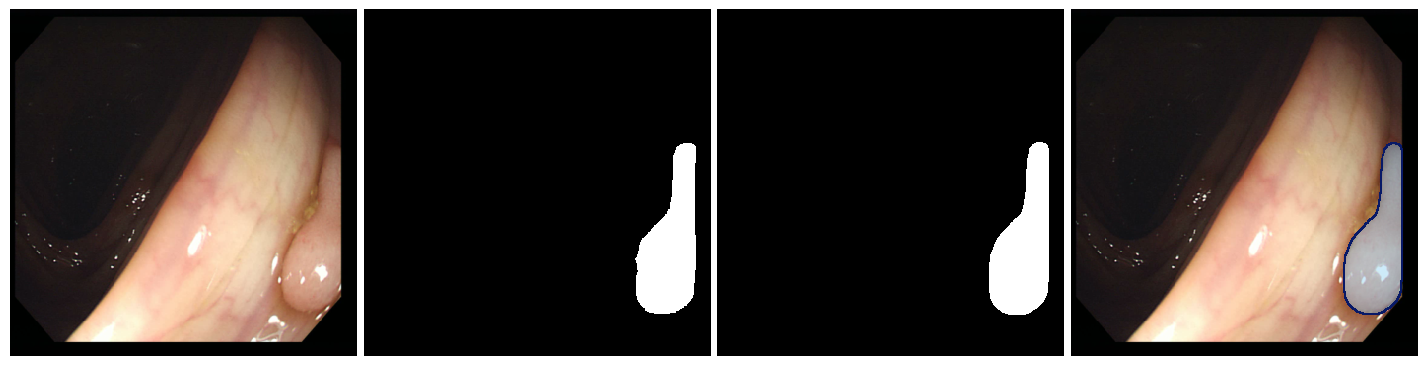

Prediction and export completed.
Prediction foreground pixels: 7028
Ground-truth foreground pixels: 6968
Output directory: /kaggle/working/segmentation_results
Download archive: /kaggle/working/segmentation_results.zip


In [31]:

import os
import zipfile
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.ndimage import binary_erosion, binary_dilation
import torchvision.transforms as T

IMAGE_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/images/100.png"
MASK_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/masks/100.png"
CHECKPOINT_PATH = "/kaggle/working/best_model.pth"
OUTPUT_DIR = "/kaggle/working/segmentation_results"

IMAGE_SIZE = (352, 352)
THRESHOLD = 0.5
FILL_COLOR = np.array([135, 206, 250], dtype=np.float32)
FILL_ALPHA = 0.4
BORDER_COLOR = np.array([8, 25, 103], dtype=np.uint8)
BORDER_WIDTH = 2

os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=True
)
model.load_state_dict(checkpoint)
model.eval()

image_transform = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image = ImageOps.exif_transpose(
    Image.open(IMAGE_PATH)
).convert("RGB")

image_352 = image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.BILINEAR
)
original = np.asarray(image_352).copy()
input_tensor = image_transform(image).unsqueeze(0).to(device)

gt_image = ImageOps.exif_transpose(
    Image.open(MASK_PATH)
).convert("L")

gt_image = gt_image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.NEAREST
)
gt_mask = (np.asarray(gt_image) > 127).astype(np.uint8)

with torch.inference_mode():
    logits = model(input_tensor)
    logits = F.interpolate(
        logits,
        size=IMAGE_SIZE,
        mode="bilinear",
        align_corners=False
    )
    probabilities = torch.sigmoid(logits)[0, 0].cpu().numpy()
    pred_mask = (probabilities >= THRESHOLD).astype(np.uint8)

overlay = original.astype(np.float32).copy()
foreground = pred_mask.astype(bool)

overlay[foreground] = (
    (1.0 - FILL_ALPHA) * overlay[foreground]
    + FILL_ALPHA * FILL_COLOR
)

boundary = foreground & ~binary_erosion(
    foreground,
    structure=np.ones((3, 3), dtype=bool),
    iterations=1,
    border_value=0
)

if BORDER_WIDTH > 1:
    boundary = binary_dilation(
        boundary,
        structure=np.ones((3, 3), dtype=bool),
        iterations=BORDER_WIDTH - 1
    ) & foreground

overlay[boundary] = BORDER_COLOR
overlay = np.clip(overlay, 0, 255).astype(np.uint8)

Image.fromarray(pred_mask * 255).save(
    os.path.join(OUTPUT_DIR, "predicted_mask.png")
)
Image.fromarray(gt_mask * 255).save(
    os.path.join(OUTPUT_DIR, "ground_truth_mask.png")
)
Image.fromarray(overlay).save(
    os.path.join(OUTPUT_DIR, "prediction_overlay.png")
)

panels = [original, gt_mask * 255, pred_mask * 255, overlay]
names = [
    "original",
    "ground_truth",
    "predicted_mask",
    "prediction_overlay"
]

fig, axes = plt.subplots(1, 4, figsize=(14.08, 3.52))

for ax, panel in zip(axes, panels):
    if panel.ndim == 2:
        ax.imshow(
            panel, cmap="gray", vmin=0, vmax=255,
            interpolation="nearest", origin="upper"
        )
    else:
        ax.imshow(panel, interpolation="nearest", origin="upper")
    ax.axis("off")

fig.subplots_adjust(
    left=0, right=1, top=1, bottom=0, wspace=0.02
)

fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.png"),
    dpi=300, bbox_inches="tight", pad_inches=0
)
fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.pdf"),
    dpi=300, bbox_inches="tight", pad_inches=0
)
plt.show()
plt.close(fig)

for name, panel in zip(names, panels):
    fig_one, ax = plt.subplots(figsize=(3.52, 3.52))

    if panel.ndim == 2:
        ax.imshow(
            panel, cmap="gray", vmin=0, vmax=255,
            interpolation="nearest", origin="upper"
        )
    else:
        ax.imshow(panel, interpolation="nearest", origin="upper")

    ax.axis("off")
    fig_one.subplots_adjust(left=0, right=1, top=1, bottom=0)

    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.png"),
        dpi=300, bbox_inches="tight", pad_inches=0
    )
    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.pdf"),
        dpi=300, bbox_inches="tight", pad_inches=0
    )
    plt.close(fig_one)

zip_path = "/kaggle/working/segmentation_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in sorted(os.listdir(OUTPUT_DIR)):
        archive.write(
            os.path.join(OUTPUT_DIR, filename),
            arcname=filename
        )

print("Prediction and export completed.")
print(f"Prediction foreground pixels: {pred_mask.sum()}")
print(f"Ground-truth foreground pixels: {gt_mask.sum()}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Download archive: {zip_path}")


# SwinUNet

In [33]:
import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    from timm.layers import DropPath, trunc_normal_
except ImportError:
    from timm.models.layers import DropPath, trunc_normal_

SWIN_T_URL = ('https://github.com/SwinTransformer/storage/releases/download/'
              'v1.0.0/swin_tiny_patch4_window7_224.pth')


class Mlp(nn.Module):
    def __init__(self, dim, hidden, drop=0.0):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden, dim)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        return self.drop(self.fc2(self.drop(self.act(self.fc1(x)))))


def window_partition(x, ws):
    B, H, W, C = x.shape
    x = x.view(B, H // ws, ws, W // ws, ws, C)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, ws, ws, C)


def window_reverse(w, ws, H, W):
    B = int(w.shape[0] / (H * W / ws / ws))
    x = w.view(B, H // ws, W // ws, ws, ws, -1)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)


class WindowAttention(nn.Module):
    def __init__(self, dim, ws, heads, qkv_bias=True, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        self.heads = heads
        self.scale = (dim // heads) ** -0.5

        self.relative_position_bias_table = nn.Parameter(
            torch.zeros((2 * ws - 1) * (2 * ws - 1), heads)
        )
        coords = torch.stack(torch.meshgrid(torch.arange(ws), torch.arange(ws), indexing='ij'))
        cf = torch.flatten(coords, 1)
        rel = (cf[:, :, None] - cf[:, None, :]).permute(1, 2, 0).contiguous()
        rel[:, :, 0] += ws - 1
        rel[:, :, 1] += ws - 1
        rel[:, :, 0] *= 2 * ws - 1
        self.register_buffer('relative_position_index', rel.sum(-1))

        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)
        trunc_normal_(self.relative_position_bias_table, std=0.02)

    def forward(self, x, mask=None):
        B_, N, C = x.shape
        qkv = self.qkv(x).reshape(B_, N, 3, self.heads, C // self.heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q * self.scale) @ k.transpose(-2, -1)

        bias = self.relative_position_bias_table[self.relative_position_index.view(-1)]
        attn = attn + bias.view(N, N, -1).permute(2, 0, 1).unsqueeze(0)

        if mask is not None:
            nW = mask.shape[0]
            attn = attn.view(B_ // nW, nW, self.heads, N, N) + mask.unsqueeze(1).unsqueeze(0)
            attn = attn.view(-1, self.heads, N, N)

        attn = self.attn_drop(attn.softmax(dim=-1))
        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        return self.proj_drop(self.proj(x))


class SwinBlock(nn.Module):
    def __init__(self, dim, res, heads, ws=7, shift=0, mlp_ratio=4.0,
                 drop=0.0, attn_drop=0.0, drop_path=0.0):
        super().__init__()
        self.res = res
        self.ws = ws
        self.shift = shift
        if min(res) <= ws:                       # window covers the whole map: no shift
            self.shift = 0
            self.ws = min(res)

        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, self.ws, heads, attn_drop=attn_drop, proj_drop=drop)
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = Mlp(dim, int(dim * mlp_ratio), drop)

        if self.shift > 0:
            H, W = res
            img_mask = torch.zeros((1, H, W, 1))
            slices = (slice(0, -self.ws), slice(-self.ws, -self.shift), slice(-self.shift, None))
            cnt = 0
            for h in slices:
                for w in slices:
                    img_mask[:, h, w, :] = cnt
                    cnt += 1
            mw = window_partition(img_mask, self.ws).view(-1, self.ws * self.ws)
            am = mw.unsqueeze(1) - mw.unsqueeze(2)
            am = am.masked_fill(am != 0, -100.0).masked_fill(am == 0, 0.0)
        else:
            am = None
        self.register_buffer('attn_mask', am)

    def forward(self, x):
        H, W = self.res
        B, L, C = x.shape
        shortcut = x
        x = self.norm1(x).view(B, H, W, C)
        if self.shift > 0:
            x = torch.roll(x, shifts=(-self.shift, -self.shift), dims=(1, 2))
        xw = window_partition(x, self.ws).view(-1, self.ws * self.ws, C)
        xw = self.attn(xw, self.attn_mask)
        x = window_reverse(xw.view(-1, self.ws, self.ws, C), self.ws, H, W)
        if self.shift > 0:
            x = torch.roll(x, shifts=(self.shift, self.shift), dims=(1, 2))
        x = shortcut + self.drop_path(x.view(B, H * W, C))
        return x + self.drop_path(self.mlp(self.norm2(x)))


class PatchEmbed(nn.Module):
    def __init__(self, in_channels=3, embed_dim=96, patch_size=4):
        super().__init__()
        self.proj = nn.Conv2d(in_channels, embed_dim, patch_size, stride=patch_size)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        return self.norm(self.proj(x).flatten(2).transpose(1, 2))


class PatchMerging(nn.Module):
    def __init__(self, res, dim):
        super().__init__()
        self.res = res
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
        self.norm = nn.LayerNorm(4 * dim)

    def forward(self, x):
        H, W = self.res
        B, L, C = x.shape
        x = x.view(B, H, W, C)
        x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2],
                       x[:, 0::2, 1::2], x[:, 1::2, 1::2]], dim=-1).view(B, -1, 4 * C)
        return self.reduction(self.norm(x))


class PatchExpand(nn.Module):
    """x2 upsampling: dim -> dim/2, resolution doubled."""
    def __init__(self, res, dim):
        super().__init__()
        self.res = res
        self.expand = nn.Linear(dim, 2 * dim, bias=False)
        self.norm = nn.LayerNorm(dim // 2)

    def forward(self, x):
        H, W = self.res
        B, L, C = x.shape
        x = self.expand(x).view(B, H, W, 2, 2, C // 2).permute(0, 1, 3, 2, 4, 5)
        return self.norm(x.reshape(B, -1, C // 2))


class FinalPatchExpand_X4(nn.Module):
    """x4 upsampling back to full resolution, channels unchanged."""
    def __init__(self, res, dim):
        super().__init__()
        self.res = res
        self.expand = nn.Linear(dim, 16 * dim, bias=False)
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        H, W = self.res
        B, L, C = x.shape
        x = self.expand(x).view(B, H, W, 4, 4, C).permute(0, 1, 3, 2, 4, 5)
        return self.norm(x.reshape(B, -1, C))


class BasicLayer(nn.Module):
    def __init__(self, dim, res, depth, heads, ws, mlp_ratio, drop, attn_drop, drop_path, downsample):
        super().__init__()
        self.blocks = nn.ModuleList([
            SwinBlock(dim, res, heads, ws, 0 if i % 2 == 0 else ws // 2,
                      mlp_ratio, drop, attn_drop, drop_path[i])
            for i in range(depth)
        ])
        self.downsample = PatchMerging(res, dim) if downsample else None

    def forward(self, x):
        for blk in self.blocks:
            x = blk(x)
        return self.downsample(x) if self.downsample is not None else x


class BasicLayerUp(nn.Module):
    def __init__(self, dim, res, depth, heads, ws, mlp_ratio, drop, attn_drop, drop_path, upsample):
        super().__init__()
        self.blocks = nn.ModuleList([
            SwinBlock(dim, res, heads, ws, 0 if i % 2 == 0 else ws // 2,
                      mlp_ratio, drop, attn_drop, drop_path[i])
            for i in range(depth)
        ])
        self.upsample = PatchExpand(res, dim) if upsample else None

    def forward(self, x):
        for blk in self.blocks:
            x = blk(x)
        return self.upsample(x) if self.upsample is not None else x


class SwinUnet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, img_size=224, patch_size=4,
                 embed_dim=96, depths=(2, 2, 2, 2), num_heads=(3, 6, 12, 24),
                 window_size=7, mlp_ratio=4.0, drop_rate=0.0, attn_drop_rate=0.0,
                 drop_path_rate=0.1, pretrained=True, pretrained_path=None,
                 pretrained_url=SWIN_T_URL):
        super().__init__()
        self.img_size = img_size
        self.in_channels = in_channels
        n = len(depths)
        g = img_size // patch_size

        for i in range(n):
            r = g // 2 ** i
            if r > window_size and r % window_size != 0:
                raise ValueError(
                    f"Stage {i} resolution {r} is not divisible by window_size={window_size}. "
                    f"Use img_size=224 with window 7, or 256 with window 8."
                )

        self.patch_embed = PatchEmbed(in_channels, embed_dim, patch_size)
        self.pos_drop = nn.Dropout(drop_rate)
        dpr = torch.linspace(0, drop_path_rate, sum(depths)).tolist()

        # Encoder
        self.layers = nn.ModuleList([
            BasicLayer(embed_dim * 2 ** i, (g // 2 ** i,) * 2, depths[i], num_heads[i],
                       window_size, mlp_ratio, drop_rate, attn_drop_rate,
                       dpr[sum(depths[:i]):sum(depths[:i + 1])], downsample=(i < n - 1))
            for i in range(n)
        ])
        self.norm = nn.LayerNorm(embed_dim * 2 ** (n - 1))

        # Decoder
        self.layers_up = nn.ModuleList()
        self.concat_back_dim = nn.ModuleList()
        for i in range(n):
            j = n - 1 - i
            dim = embed_dim * 2 ** j
            res = (g // 2 ** j,) * 2
            if i == 0:
                self.layers_up.append(PatchExpand(res, dim))
                self.concat_back_dim.append(nn.Identity())
            else:
                self.concat_back_dim.append(nn.Linear(2 * dim, dim))
                self.layers_up.append(
                    BasicLayerUp(dim, res, depths[j], num_heads[j], window_size, mlp_ratio,
                                 drop_rate, attn_drop_rate,
                                 dpr[sum(depths[:j]):sum(depths[:j + 1])], upsample=(i < n - 1))
                )
        self.norm_up = nn.LayerNorm(embed_dim)
        self.up = FinalPatchExpand_X4((g, g), embed_dim)
        self.output = nn.Conv2d(embed_dim, out_channels, 1, bias=False)

        self.apply(self._init_weights)

        # Pretrained loading: local file takes priority, otherwise download.
        # Any failure raises, so the model never silently falls back to random weights.
        if pretrained_path is not None:
            self._load_checkpoint(torch.load(pretrained_path, map_location='cpu'))
        elif pretrained:
            ckpt = torch.hub.load_state_dict_from_url(pretrained_url, map_location='cpu', progress=True)
            self._load_checkpoint(ckpt)
        else:
            print("SwinUnet: no pretrained weights, training from scratch.")

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    def _load_checkpoint(self, ckpt, min_matched=100):
        """Load official Swin-T ImageNet weights into the encoder and mirror them into the
        decoder (layers.i -> layers_up.(3-i)). Relative-position bias tables are resized
        (bicubic) when the window size differs from the checkpoint's (7)."""
        sd = ckpt['model'] if 'model' in ckpt else ckpt
        full = {k: v for k, v in sd.items()
                if 'attn_mask' not in k and 'relative_position_index' not in k}
        for k, v in list(full.items()):
            if k.startswith('layers.'):
                idx = int(k.split('.')[1])
                full['layers_up.' + str(3 - idx) + k[len('layers.' + str(idx)):]] = v
    
        own = self.state_dict()
    
        # resize relative position bias tables if the window size differs
        for k in list(full.keys()):
            if 'relative_position_bias_table' in k and k in own and full[k].shape != own[k].shape:
                old = full[k]
                n_old, n_new = int(old.shape[0] ** 0.5), int(own[k].shape[0] ** 0.5)
                h = old.shape[1]
                t = old.permute(1, 0).reshape(1, h, n_old, n_old)
                t = F.interpolate(t, size=(n_new, n_new), mode='bicubic', align_corners=False)
                full[k] = t.reshape(h, n_new * n_new).permute(1, 0)
    
        keep = {k: v for k, v in full.items() if k in own and own[k].shape == v.shape}
        if len(keep) < min_matched:
            raise RuntimeError(
                f"Only {len(keep)} tensors matched the checkpoint; it is probably not the "
                f"official Swin-T .pth (timm-format keys differ). Model would be near-random."
            )
        self.load_state_dict(keep, strict=False)
        print(f"Swin-T ImageNet weights loaded: {len(keep)} tensors matched")

    def forward(self, x):
        H, W = x.shape[2:]
        if (H, W) != (self.img_size, self.img_size):
            raise ValueError(f"Input must be {self.img_size}x{self.img_size}, got {H}x{W}.")
        if x.shape[1] == 1 and self.in_channels == 3:
            x = x.repeat(1, 3, 1, 1)

        x = self.pos_drop(self.patch_embed(x))
        skips = []
        for layer in self.layers:
            skips.append(x)
            x = layer(x)
        x = self.norm(x)

        for i, layer in enumerate(self.layers_up):
            if i == 0:
                x = layer(x)
            else:
                x = torch.cat([x, skips[len(skips) - 1 - i]], dim=-1)
                x = self.concat_back_dim[i](x)
                x = layer(x)

        x = self.up(self.norm_up(x))
        B, L, C = x.shape
        x = x.view(B, H, W, C).permute(0, 3, 1, 2)
        return self.output(x)

    def param_groups(self, lr_enc=1e-4, lr_dec=3e-4):
        enc = (list(self.patch_embed.parameters()) + list(self.layers.parameters())
               + list(self.norm.parameters()))
        enc_ids = {id(p) for p in enc}
        dec = [p for p in self.parameters() if id(p) not in enc_ids]
        return [{'params': enc, 'lr': lr_enc}, {'params': dec, 'lr': lr_dec}]


model = SwinUnet(
    in_channels=3,
    out_channels=1,
    img_size=352,
    window_size=11,
    pretrained=True
).to(device)

with torch.no_grad():
    y = model(torch.randn(2, 3, 352, 352, device=device))
print(y.shape, f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M params")

Swin-T ImageNet weights loaded: 197 tensors matched
torch.Size([2, 1, 352, 352]) 27.20M params


In [34]:

import time
import pandas as pd
import torch


def count_params(m):
    return (
        sum(p.numel() for p in m.parameters()),
        sum(p.numel() for p in m.parameters() if p.requires_grad)
    )


@torch.no_grad()
def latency(m, x, warmup=20, runs=50):
    m.eval()

    for _ in range(warmup):
        _ = m(x)

    if x.is_cuda:
        torch.cuda.synchronize()

    t = time.perf_counter()

    for _ in range(runs):
        _ = m(x)

    if x.is_cuda:
        torch.cuda.synchronize()

    ms = (time.perf_counter() - t) / runs * 1000
    return ms, 1000 / ms


@torch.no_grad()
def flops(m, x):
    activities = [torch.profiler.ProfilerActivity.CPU]

    if x.is_cuda:
        activities.append(torch.profiler.ProfilerActivity.CUDA)

    m.eval()

    with torch.profiler.profile(
        activities=activities,
        with_flops=True
    ) as prof:
        _ = m(x)

    return sum(
        getattr(event, "flops", 0) or 0
        for event in prof.key_averages()
    ) / 1e9


@torch.no_grad()
def peak_gpu_memory(m, x):
    if not x.is_cuda:
        return None

    m.eval()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(x.device)

    _ = m(x)
    torch.cuda.synchronize(x.device)

    return torch.cuda.max_memory_allocated(x.device) / 1024**2


def efficiency(name, m, x):
    n, trainable = count_params(m)
    g = flops(m, x)
    ms, fps = latency(m, x)
    mem = peak_gpu_memory(m, x)

    result = {
        "Model": name,
        "Params(M)": n / 1e6,
        "Trainable(M)": trainable / 1e6,
        "GFLOPs": g,
        "Latency(ms)": ms,
        "FPS": fps,
        "GPU(MB)": mem
    }

    msg = (
        f"{name}: Params={n / 1e6:.3f}M | "
        f"Trainable={trainable / 1e6:.3f}M | "
        f"GFLOPs={g:.3f} | Latency={ms:.2f}ms | "
        f"FPS={fps:.2f}"
    )

    if mem is not None:
        msg += f" | GPU={mem:.1f}MB"

    print(msg)
    return result


model = SwinUnet(
    in_channels=3,
    out_channels=1,
    img_size=352,
    window_size=11,
    pretrained=True
).to(device)

dummy = torch.randn(1, 3, 352, 352, device=device)

result = efficiency("Swin-Unet", model, dummy)

print("\nParameter breakdown:")
for name, module in [
    ("Patch embedding", model.patch_embed),
    ("Encoder", model.layers),
    ("Encoder norm", model.norm),
    ("Decoder", model.layers_up),
    ("Skip projections", model.concat_back_dim),
    ("Final upsampling", model.up),
    ("Output head", model.output),
]:
    p, t = count_params(module)
    print(f"{name:<20}: {p / 1e6:.3f}M total | {t / 1e6:.3f}M trainable")

efficiency_df = pd.DataFrame([result])
print("\n", efficiency_df.to_string(index=False))

Swin-T ImageNet weights loaded: 197 tensors matched
Swin-Unet: Params=27.204M | Trainable=27.204M | GFLOPs=31.583 | Latency=21.65ms | FPS=46.19 | GPU=1154.3MB

Parameter breakdown:
Patch embedding     : 0.005M total | 0.005M trainable
Encoder             : 20.431M total | 20.431M trainable
Encoder norm        : 0.002M total | 0.002M trainable
Decoder             : 6.230M total | 6.230M trainable
Skip projections    : 0.388M total | 0.388M trainable
Final upsampling    : 0.148M total | 0.148M trainable
Output head         : 0.000M total | 0.000M trainable

     Model  Params(M)  Trainable(M)    GFLOPs  Latency(ms)       FPS    GPU(MB)
Swin-Unet  27.204036     27.204036 31.583178     21.65113 46.186965 1154.32373


In [35]:
import random, math, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


class StructureDiceLoss(nn.Module):
    def __init__(self, dice_w=0.5):
        super().__init__()
        self.dice_w = dice_w

    def forward(self, logits, targets):
        t = targets.unsqueeze(1).float()
        weit = 1 + 5 * torch.abs(F.avg_pool2d(t, 31, 1, 15) - t)
        wbce = (F.binary_cross_entropy_with_logits(logits, t, reduction='none') * weit).sum((2, 3)) / weit.sum((2, 3))
        p = torch.sigmoid(logits)
        inter = (p * t * weit).sum((2, 3))
        union = ((p + t) * weit).sum((2, 3))
        wiou = 1 - (inter + 1) / (union - inter + 1)
        inter_d = (p * t).sum((2, 3))
        den = p.sum((2, 3)) + t.sum((2, 3))
        dice = 1 - (2 * inter_d + 1e-6) / (den + 1e-6)
        return (wbce + wiou).mean() + self.dice_w * dice.mean()


criterion = StructureDiceLoss().to(device)

num_epochs = 150
optimizer = torch.optim.AdamW(
    model.param_groups(lr_enc=1e-4, lr_dec=3e-4),
    weight_decay=1e-4
)

warmup_epochs = 5

def lr_lambda(ep):
    if ep < warmup_epochs:
        return (ep + 1) / warmup_epochs
    prog = (ep - warmup_epochs) / max(1, num_epochs - warmup_epochs)
    return max(0.01, 0.5 * (1 + math.cos(math.pi * prog)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

ema = copy.deepcopy(model).to(device)
ema.eval()

for p in ema.parameters():
    p.requires_grad_(False)

ema_decay = 0.995

@torch.no_grad()
def ema_update(ema_m, src, decay):
    for pe, ps in zip(ema_m.parameters(), src.parameters()):
        pe.mul_(decay).add_(ps.detach(), alpha=1 - decay)
    for be, bs in zip(ema_m.buffers(), src.buffers()):
        be.copy_(bs)


@torch.no_grad()
def evaluate(m, loader):
    m.eval()
    n = 0
    vl = vd = vi = 0.0

    for imgs, masks, _ in loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = m(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(preds, size=masks.shape[-2:], mode='bilinear', align_corners=False)

        b = imgs.size(0)
        vl += criterion(preds, masks).item() * b
        vd += dice_score(preds, masks).item() * b
        vi += iou_score(preds, masks).item() * b
        n += b

    return vl / n, vd / n, vi / n


class EarlyStopping:
    def __init__(self, patience=40, min_epochs=40, verbose=True):
        self.patience, self.min_epochs, self.verbose = patience, min_epochs, verbose
        self.counter, self.best, self.stop = 0, None, False

    def __call__(self, score, model_to_save, epoch):
        if self.best is None or score > self.best + 1e-4:
            self.best, self.counter = score, 0
            torch.save(model_to_save.state_dict(), "best_model.pth")
            if self.verbose:
                print(f"Val Dice improved to {self.best:.4f} - EMA model saved.")
        else:
            self.counter += 1
            if self.verbose:
                print(f"No improvement. EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience and (epoch + 1) >= self.min_epochs:
                print("Early stopping triggered.")
                self.stop = True


early_stopping = EarlyStopping(patience=40, min_epochs=40, verbose=True)

train_losses, val_losses = [], []
train_dices, val_dices = [], []
train_ious, val_ious = [], []

global_step = 0

for epoch in range(num_epochs):
    model.train()
    train_loss = train_dice = train_iou = 0.0

    for imgs, masks, labels in train_loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = model(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(preds, size=masks.shape[-2:], mode='bilinear', align_corners=False)

        loss = criterion(preds, masks)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        global_step += 1
        ema_update(ema, model, min(ema_decay, (1 + global_step) / (10 + global_step)))

        train_loss += loss.item()
        train_dice += dice_score(preds.detach(), masks).item()
        train_iou += iou_score(preds.detach(), masks).item()

    val_loss, val_dice, val_iou = evaluate(ema, val_loader)

    avg_train_loss = train_loss / len(train_loader)
    avg_train_dice = train_dice / len(train_loader)
    avg_train_iou = train_iou / len(train_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(val_loss)
    train_dices.append(avg_train_dice)
    val_dices.append(val_dice)
    train_ious.append(avg_train_iou)
    val_ious.append(val_iou)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Train Dice: {avg_train_dice:.4f} | Val Dice: {val_dice:.4f} | "
        f"Train IoU: {avg_train_iou:.4f} | Val IoU: {val_iou:.4f} | "
        f"LR(enc): {optimizer.param_groups[0]['lr']:.2e}"
    )

    scheduler.step()
    early_stopping(val_dice, ema, epoch)

    if early_stopping.stop:
        print(f"\nTraining stopped early at epoch {epoch+1}.")
        break

model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()
print(f"\nBest EMA model loaded (best val Dice {early_stopping.best:.4f}).")

Epoch [1/150] Train Loss: 1.7444 | Val Loss: 1.5829 | Train Dice: 0.1168 | Val Dice: 0.2614 | Train IoU: 0.0714 | Val IoU: 0.1627 | LR(enc): 2.00e-05
Val Dice improved to 0.2614 - EMA model saved.
Epoch [2/150] Train Loss: 1.3543 | Val Loss: 1.1215 | Train Dice: 0.4613 | Val Dice: 0.5500 | Train IoU: 0.3324 | Val IoU: 0.4029 | LR(enc): 4.00e-05
Val Dice improved to 0.5500 - EMA model saved.
Epoch [3/150] Train Loss: 1.0076 | Val Loss: 0.8684 | Train Dice: 0.6467 | Val Dice: 0.6601 | Train IoU: 0.5152 | Val IoU: 0.5232 | LR(enc): 6.00e-05
Val Dice improved to 0.6601 - EMA model saved.
Epoch [4/150] Train Loss: 0.8692 | Val Loss: 0.6864 | Train Dice: 0.6960 | Val Dice: 0.7494 | Train IoU: 0.5779 | Val IoU: 0.6316 | LR(enc): 8.00e-05
Val Dice improved to 0.7494 - EMA model saved.
Epoch [5/150] Train Loss: 0.6754 | Val Loss: 0.5879 | Train Dice: 0.7789 | Val Dice: 0.7882 | Train IoU: 0.6739 | Val IoU: 0.6889 | LR(enc): 1.00e-04
Val Dice improved to 0.7882 - EMA model saved.
Epoch [6/150] T

In [36]:
import numpy as np
import torch
import torch.nn.functional as F
from scipy import ndimage


def _get_boundary(mask):
    mask = mask.astype(bool)
    if not mask.any():
        return np.zeros_like(mask, dtype=bool)
    eroded = ndimage.binary_erosion(mask, structure=np.ones((3, 3)))
    return mask ^ eroded


def _surface_distances(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    pred_surface, gt_surface = _get_boundary(pred), _get_boundary(gt)

    if not pred.any() and not gt.any():
        return np.array([0.0]), np.array([0.0])
    if not pred.any() or not gt.any():
        h, w = pred.shape
        max_dist = np.sqrt(h**2 + w**2)
        return np.array([max_dist]), np.array([max_dist])

    dt_gt = ndimage.distance_transform_edt(~gt_surface)
    dt_pred = ndimage.distance_transform_edt(~pred_surface)
    return dt_gt[pred_surface], dt_pred[gt_surface]


def _assd(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return (np.mean(d1) + np.mean(d2)) / 2.0


def _hd95(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return np.percentile(np.concatenate([d1, d2]), 95)


def _bf1(pred, gt, tolerance=2):
    pred_boundary, gt_boundary = _get_boundary(pred), _get_boundary(gt)
    pred_count, gt_count = pred_boundary.sum(), gt_boundary.sum()

    if pred_count == 0 and gt_count == 0:
        return 1.0
    if pred_count == 0 or gt_count == 0:
        return 0.0

    dt_gt = ndimage.distance_transform_edt(~gt_boundary)
    dt_pred = ndimage.distance_transform_edt(~pred_boundary)
    precision = (dt_gt[pred_boundary] <= tolerance).sum() / (pred_count + 1e-6)
    recall = (dt_pred[gt_boundary] <= tolerance).sum() / (gt_count + 1e-6)
    return 2 * precision * recall / (precision + recall + 1e-6)


def evaluate_segmentation(model, test_loader, device, thr=0.4, seed=42):
    model.eval()
    model.to(device)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    rows = []

    with torch.no_grad():
        for imgs, masks, labels in test_loader:
            imgs = imgs.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.long)
            outputs = model(imgs)

            if outputs.shape[-2:] != masks.shape[-2:]:
                outputs = F.interpolate(
                    outputs, size=masks.shape[-2:],
                    mode='bilinear', align_corners=False
                )

            preds = (torch.sigmoid(outputs) > thr).squeeze(1)
            gts = masks.bool()

            for b in range(preds.shape[0]):
                p, g = preds[b], gts[b]
                tp = (p & g).sum().item()
                fp = (p & ~g).sum().item()
                fn = (~p & g).sum().item()
                e = 1e-6

                pn = p.cpu().numpy()
                gn = g.cpu().numpy()

                rows.append({
                    "dice": (2 * tp + e) / (2 * tp + fp + fn + e),
                    "iou": (tp + e) / (tp + fp + fn + e),
                    "prec": (tp + e) / (tp + fp + e),
                    "rec": (tp + e) / (tp + fn + e),
                    "bf1": _bf1(pn, gn, tolerance=2),
                    "assd": _assd(pn, gn),
                    "hd95": _hd95(pn, gn)
                })

    if not rows:
        raise ValueError("The test_loader is empty.")

    M = {k: np.array([r[k] for r in rows]) for k in rows[0]}

    print("\n============ Test Set (per-image, polyp class) ============")
    print(f"  Dice      : {M['dice'].mean():.4f}")
    print(f"  IoU       : {M['iou'].mean():.4f}")
    print(f"  Precision : {M['prec'].mean():.4f}")
    print(f"  Recall    : {M['rec'].mean():.4f}")
    print(f"  BF1       : {M['bf1'].mean():.4f}")
    print(f"  ASSD      : {M['assd'].mean():.4f} px")
    print(f"  HD95      : {M['hd95'].mean():.4f} px")
    print("===========================================================\n")

    return {**{k: float(v.mean()) for k, v in M.items()}, "per_image": M}


results = evaluate_segmentation(model, test_loader, device=device, thr=0.4)


============ Test Set (per-image, polyp class) ============
  Dice      : 0.9070
  IoU       : 0.8466
  Precision : 0.8875
  Recall    : 0.9331
  BF1       : 0.6642
  ASSD      : 3.6079 px
  HD95      : 14.8227 px



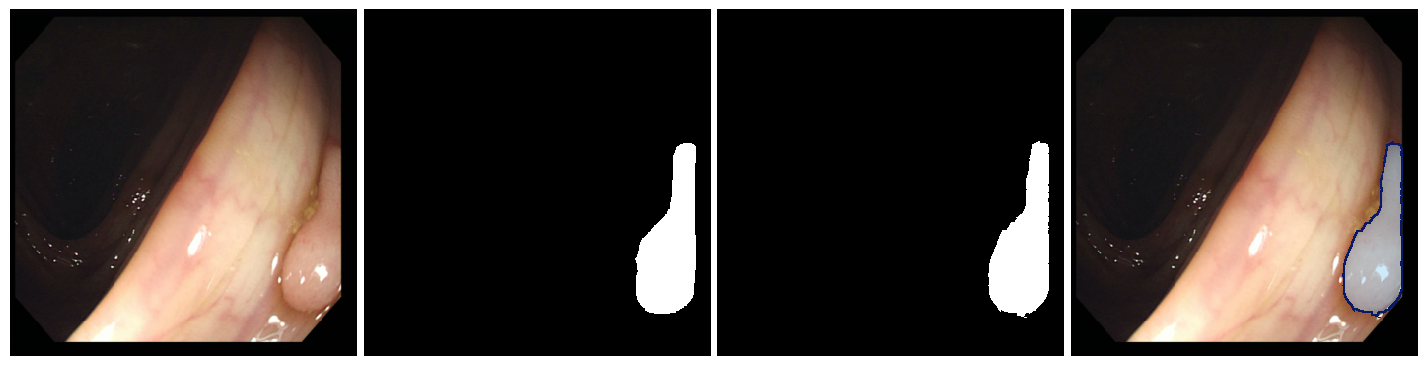

Prediction and export completed.
Prediction foreground pixels: 6840
Ground-truth foreground pixels: 6968
Output directory: /kaggle/working/segmentation_results
Download archive: /kaggle/working/segmentation_results.zip


In [37]:

import os
import zipfile
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.ndimage import binary_erosion, binary_dilation
import torchvision.transforms as T

IMAGE_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/images/100.png"
MASK_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/masks/100.png"
CHECKPOINT_PATH = "/kaggle/working/best_model.pth"
OUTPUT_DIR = "/kaggle/working/segmentation_results"

IMAGE_SIZE = (352, 352)
THRESHOLD = 0.5
FILL_COLOR = np.array([135, 206, 250], dtype=np.float32)
FILL_ALPHA = 0.4
BORDER_COLOR = np.array([8, 25, 103], dtype=np.uint8)
BORDER_WIDTH = 2

os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=True
)
model.load_state_dict(checkpoint)
model.eval()

image_transform = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image = ImageOps.exif_transpose(
    Image.open(IMAGE_PATH)
).convert("RGB")

image_352 = image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.BILINEAR
)
original = np.asarray(image_352).copy()
input_tensor = image_transform(image).unsqueeze(0).to(device)

gt_image = ImageOps.exif_transpose(
    Image.open(MASK_PATH)
).convert("L")

gt_image = gt_image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.NEAREST
)
gt_mask = (np.asarray(gt_image) > 127).astype(np.uint8)

with torch.inference_mode():
    logits = model(input_tensor)
    logits = F.interpolate(
        logits,
        size=IMAGE_SIZE,
        mode="bilinear",
        align_corners=False
    )
    probabilities = torch.sigmoid(logits)[0, 0].cpu().numpy()
    pred_mask = (probabilities >= THRESHOLD).astype(np.uint8)

overlay = original.astype(np.float32).copy()
foreground = pred_mask.astype(bool)

overlay[foreground] = (
    (1.0 - FILL_ALPHA) * overlay[foreground]
    + FILL_ALPHA * FILL_COLOR
)

boundary = foreground & ~binary_erosion(
    foreground,
    structure=np.ones((3, 3), dtype=bool),
    iterations=1,
    border_value=0
)

if BORDER_WIDTH > 1:
    boundary = binary_dilation(
        boundary,
        structure=np.ones((3, 3), dtype=bool),
        iterations=BORDER_WIDTH - 1
    ) & foreground

overlay[boundary] = BORDER_COLOR
overlay = np.clip(overlay, 0, 255).astype(np.uint8)

Image.fromarray(pred_mask * 255).save(
    os.path.join(OUTPUT_DIR, "predicted_mask.png")
)
Image.fromarray(gt_mask * 255).save(
    os.path.join(OUTPUT_DIR, "ground_truth_mask.png")
)
Image.fromarray(overlay).save(
    os.path.join(OUTPUT_DIR, "prediction_overlay.png")
)

panels = [original, gt_mask * 255, pred_mask * 255, overlay]
names = [
    "original",
    "ground_truth",
    "predicted_mask",
    "prediction_overlay"
]

fig, axes = plt.subplots(1, 4, figsize=(14.08, 3.52))

for ax, panel in zip(axes, panels):
    if panel.ndim == 2:
        ax.imshow(
            panel, cmap="gray", vmin=0, vmax=255,
            interpolation="nearest", origin="upper"
        )
    else:
        ax.imshow(panel, interpolation="nearest", origin="upper")
    ax.axis("off")

fig.subplots_adjust(
    left=0, right=1, top=1, bottom=0, wspace=0.02
)

fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.png"),
    dpi=300, bbox_inches="tight", pad_inches=0
)
fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.pdf"),
    dpi=300, bbox_inches="tight", pad_inches=0
)
plt.show()
plt.close(fig)

for name, panel in zip(names, panels):
    fig_one, ax = plt.subplots(figsize=(3.52, 3.52))

    if panel.ndim == 2:
        ax.imshow(
            panel, cmap="gray", vmin=0, vmax=255,
            interpolation="nearest", origin="upper"
        )
    else:
        ax.imshow(panel, interpolation="nearest", origin="upper")

    ax.axis("off")
    fig_one.subplots_adjust(left=0, right=1, top=1, bottom=0)

    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.png"),
        dpi=300, bbox_inches="tight", pad_inches=0
    )
    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.pdf"),
        dpi=300, bbox_inches="tight", pad_inches=0
    )
    plt.close(fig_one)

zip_path = "/kaggle/working/segmentation_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in sorted(os.listdir(OUTPUT_DIR)):
        archive.write(
            os.path.join(OUTPUT_DIR, filename),
            arcname=filename
        )

print("Prediction and export completed.")
print(f"Prediction foreground pixels: {pred_mask.sum()}")
print(f"Ground-truth foreground pixels: {gt_mask.sum()}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Download archive: {zip_path}")


# UNet

In [11]:

import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.final(d1)


if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = UNet(in_channels=3, out_channels=1).to(device)

    x = torch.randn(2, 3, 352, 352, device=device)

    with torch.no_grad():
        y = model(x)

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    print("Output shape:", y.shape)
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")


Output shape: torch.Size([2, 1, 352, 352])
Total parameters: 31,037,633
Trainable parameters: 31,037,633


In [12]:

import time
import pandas as pd
import torch


def count_params(m):
    return (
        sum(p.numel() for p in m.parameters()),
        sum(p.numel() for p in m.parameters() if p.requires_grad)
    )


@torch.no_grad()
def latency(m, x, warmup=20, runs=50):
    m.eval()

    for _ in range(warmup):
        _ = m(x)

    if x.is_cuda:
        torch.cuda.synchronize()

    t = time.perf_counter()

    for _ in range(runs):
        _ = m(x)

    if x.is_cuda:
        torch.cuda.synchronize()

    ms = (time.perf_counter() - t) / runs * 1000
    return ms, 1000 / ms


def flops(m, x):
    acts = [torch.profiler.ProfilerActivity.CPU]

    if x.is_cuda:
        acts.append(torch.profiler.ProfilerActivity.CUDA)

    m.eval()

    with torch.no_grad():
        with torch.profiler.profile(
            activities=acts,
            with_flops=True
        ) as p:
            _ = m(x)

    return sum(
        getattr(e, "flops", 0) or 0
        for e in p.key_averages()
    ) / 1e9


def efficiency(name, m, x):
    n, tr = count_params(m)
    g = flops(m, x)
    ms, fps = latency(m, x)

    mem = None

    if x.is_cuda:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        with torch.no_grad():
            _ = m(x)

        torch.cuda.synchronize()
        mem = torch.cuda.max_memory_allocated() / 1024**2

    r = {
        "Model": name,
        "Params(M)": n / 1e6,
        "Trainable(M)": tr / 1e6,
        "GFLOPs": g,
        "Latency(ms)": ms,
        "FPS": fps,
        "GPU(MB)": mem
    }

    msg = (
        f"{name}: Params={n/1e6:.3f}M | "
        f"Trainable={tr/1e6:.3f}M | "
        f"GFLOPs={g:.3f} | "
        f"Latency={ms:.2f}ms | FPS={fps:.2f}"
    )

    if mem is not None:
        msg += f" | GPU={mem:.1f}MB"

    print(msg)
    return r


model = UNet(
    in_channels=3,
    out_channels=1
).to(device)

model.eval()

dummy = torch.randn(
    1, 3, 352, 352,
    device=device
)

r1 = efficiency("Pure U-Net", model, dummy)


print("\nParameter breakdown:")

for name, module in [
    ("Encoder 1", model.enc1),
    ("Encoder 2", model.enc2),
    ("Encoder 3", model.enc3),
    ("Encoder 4", model.enc4),
    ("Bottleneck", model.bottleneck),
    ("Decoder 4", model.dec4),
    ("Decoder 3", model.dec3),
    ("Decoder 2", model.dec2),
    ("Decoder 1", model.dec1),
    ("Final Conv", model.final),
    ("Full Model", model)
]:
    p, t = count_params(module)

    print(
        f"{name:<16}: "
        f"{p/1e6:.3f}M total | "
        f"{t/1e6:.3f}M trainable"
    )


efficiency_df = pd.DataFrame([r1])

print("\n", efficiency_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


Pure U-Net: Params=31.038M | Trainable=31.038M | GFLOPs=174.013 | Latency=39.64ms | FPS=25.23 | GPU=361.4MB

Parameter breakdown:
Encoder 1       : 0.039M total | 0.039M trainable
Encoder 2       : 0.222M total | 0.222M trainable
Encoder 3       : 0.886M total | 0.886M trainable
Encoder 4       : 3.541M total | 3.541M trainable
Bottleneck      : 14.160M total | 14.160M trainable
Decoder 4       : 7.080M total | 7.080M trainable
Decoder 3       : 1.770M total | 1.770M trainable
Decoder 2       : 0.443M total | 0.443M trainable
Decoder 1       : 0.111M total | 0.111M trainable
Final Conv      : 0.000M total | 0.000M trainable
Full Model      : 31.038M total | 31.038M trainable

      Model  Params(M)  Trainable(M)    GFLOPs  Latency(ms)       FPS    GPU(MB)
Pure U-Net  31.037633     31.037633 174.01276    39.638999 25.227681 361.415527


In [13]:
import random
import math
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = UNet(in_channels=3, out_channels=1).to(device)

class StructureDiceLoss(nn.Module):
    def __init__(self, dice_w=0.5):
        super().__init__()
        self.dice_w = dice_w

    def forward(self, logits, targets):
        t = targets.unsqueeze(1).float()

        weit = 1 + 5 * torch.abs(
            F.avg_pool2d(t, 31, 1, 15) - t
        )

        wbce = (
            F.binary_cross_entropy_with_logits(
                logits, t, reduction="none"
            ) * weit
        ).sum((2, 3)) / weit.sum((2, 3))

        p = torch.sigmoid(logits)

        inter = (p * t * weit).sum((2, 3))
        union = ((p + t) * weit).sum((2, 3))
        wiou = 1 - (inter + 1) / (union - inter + 1)

        inter_d = (p * t).sum((2, 3))
        den = p.sum((2, 3)) + t.sum((2, 3))
        dice = 1 - (2 * inter_d + 1e-6) / (den + 1e-6)

        return (wbce + wiou).mean() + self.dice_w * dice.mean()


criterion = StructureDiceLoss().to(device)

num_epochs = 150

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

warmup_epochs = 5

def lr_lambda(ep):
    if ep < warmup_epochs:
        return (ep + 1) / warmup_epochs

    prog = (ep - warmup_epochs) / max(
        1, num_epochs - warmup_epochs
    )

    return max(
        0.01,
        0.5 * (1 + math.cos(math.pi * prog))
    )

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lr_lambda
)

ema = copy.deepcopy(model).to(device)
ema.eval()

for p in ema.parameters():
    p.requires_grad_(False)

ema_decay = 0.995

@torch.no_grad()
def ema_update(ema_m, src, decay):
    for pe, ps in zip(ema_m.parameters(), src.parameters()):
        pe.mul_(decay).add_(ps.detach(), alpha=1 - decay)

    for be, bs in zip(ema_m.buffers(), src.buffers()):
        be.copy_(bs)


@torch.no_grad()
def evaluate(m, loader):
    m.eval()

    n = 0
    vl = vd = vi = 0.0

    for imgs, masks, _ in loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = m(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(
                preds,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        b = imgs.size(0)

        vl += criterion(preds, masks).item() * b
        vd += dice_score(preds, masks).item() * b
        vi += iou_score(preds, masks).item() * b
        n += b

    return vl / n, vd / n, vi / n


class EarlyStopping:
    def __init__(self, patience=40, min_epochs=40, verbose=True):
        self.patience = patience
        self.min_epochs = min_epochs
        self.verbose = verbose
        self.counter = 0
        self.best = None
        self.stop = False

    def __call__(self, score, model_to_save, epoch):
        if self.best is None or score > self.best + 1e-4:
            self.best = score
            self.counter = 0

            torch.save(
                model_to_save.state_dict(),
                "best_unet_ema.pth"
            )

            if self.verbose:
                print(
                    f"Val Dice improved to {self.best:.4f} "
                    "- EMA model saved."
                )
        else:
            self.counter += 1

            if self.verbose:
                print(
                    f"No improvement. EarlyStopping counter: "
                    f"{self.counter}/{self.patience}"
                )

            if (
                self.counter >= self.patience
                and (epoch + 1) >= self.min_epochs
            ):
                print("Early stopping triggered.")
                self.stop = True


early_stopping = EarlyStopping(
    patience=40,
    min_epochs=40,
    verbose=True
)

train_losses, val_losses = [], []
train_dices, val_dices = [], []
train_ious, val_ious = [], []

global_step = 0

for epoch in range(num_epochs):
    model.train()

    train_loss = train_dice = train_iou = 0.0

    for imgs, masks, labels in train_loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = model(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(
                preds,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        loss = criterion(preds, masks)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        global_step += 1

        ema_update(
            ema,
            model,
            min(ema_decay, (1 + global_step) / (10 + global_step))
        )

        train_loss += loss.item()
        train_dice += dice_score(preds.detach(), masks).item()
        train_iou += iou_score(preds.detach(), masks).item()

    val_loss, val_dice, val_iou = evaluate(ema, val_loader)

    avg_train_loss = train_loss / len(train_loader)
    avg_train_dice = train_dice / len(train_loader)
    avg_train_iou = train_iou / len(train_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(val_loss)
    train_dices.append(avg_train_dice)
    val_dices.append(val_dice)
    train_ious.append(avg_train_iou)
    val_ious.append(val_iou)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {avg_train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Train IoU: {avg_train_iou:.4f} | "
        f"Val IoU: {val_iou:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.2e}"
    )

    scheduler.step()
    early_stopping(val_dice, ema, epoch)

    if early_stopping.stop:
        print(f"\nTraining stopped early at epoch {epoch+1}.")
        break

checkpoint = torch.load(
    "best_unet_ema.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.eval()

print(
    f"\nBest EMA U-Net model loaded "
    f"(best validation Dice: {early_stopping.best:.4f})."
)

Epoch [1/150] Train Loss: 1.9277 | Val Loss: 1.9218 | Train Dice: 0.1884 | Val Dice: 0.1254 | Train IoU: 0.1206 | Val IoU: 0.0699 | LR: 6.00e-05
Val Dice improved to 0.1254 - EMA model saved.
Epoch [2/150] Train Loss: 1.7858 | Val Loss: 1.7951 | Train Dice: 0.2532 | Val Dice: 0.2270 | Train IoU: 0.1640 | Val IoU: 0.1460 | LR: 1.20e-04
Val Dice improved to 0.2270 - EMA model saved.
Epoch [3/150] Train Loss: 1.6933 | Val Loss: 1.7181 | Train Dice: 0.3147 | Val Dice: 0.2801 | Train IoU: 0.2081 | Val IoU: 0.1981 | LR: 1.80e-04
Val Dice improved to 0.2801 - EMA model saved.
Epoch [4/150] Train Loss: 1.6315 | Val Loss: 1.6693 | Train Dice: 0.3581 | Val Dice: 0.2899 | Train IoU: 0.2499 | Val IoU: 0.2131 | LR: 2.40e-04
Val Dice improved to 0.2899 - EMA model saved.
Epoch [5/150] Train Loss: 1.5803 | Val Loss: 1.6238 | Train Dice: 0.3810 | Val Dice: 0.2757 | Train IoU: 0.2679 | Val IoU: 0.1972 | LR: 3.00e-04
No improvement. EarlyStopping counter: 1/40
Epoch [6/150] Train Loss: 1.4834 | Val Loss

In [14]:
import numpy as np
import torch
import torch.nn.functional as F
from scipy import ndimage


def _get_boundary(mask):
    mask = mask.astype(bool)
    if not mask.any():
        return np.zeros_like(mask, dtype=bool)
    eroded = ndimage.binary_erosion(mask, structure=np.ones((3, 3)))
    return mask ^ eroded


def _surface_distances(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    pred_surface, gt_surface = _get_boundary(pred), _get_boundary(gt)

    if not pred.any() and not gt.any():
        return np.array([0.0]), np.array([0.0])
    if not pred.any() or not gt.any():
        h, w = pred.shape
        max_dist = np.sqrt(h**2 + w**2)
        return np.array([max_dist]), np.array([max_dist])

    dt_gt = ndimage.distance_transform_edt(~gt_surface)
    dt_pred = ndimage.distance_transform_edt(~pred_surface)
    return dt_gt[pred_surface], dt_pred[gt_surface]


def _assd(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return (np.mean(d1) + np.mean(d2)) / 2.0


def _hd95(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return np.percentile(np.concatenate([d1, d2]), 95)


def _bf1(pred, gt, tolerance=2):
    pred_boundary, gt_boundary = _get_boundary(pred), _get_boundary(gt)
    pred_count, gt_count = pred_boundary.sum(), gt_boundary.sum()

    if pred_count == 0 and gt_count == 0:
        return 1.0
    if pred_count == 0 or gt_count == 0:
        return 0.0

    dt_gt = ndimage.distance_transform_edt(~gt_boundary)
    dt_pred = ndimage.distance_transform_edt(~pred_boundary)
    precision = (dt_gt[pred_boundary] <= tolerance).sum() / (pred_count + 1e-6)
    recall = (dt_pred[gt_boundary] <= tolerance).sum() / (gt_count + 1e-6)
    return 2 * precision * recall / (precision + recall + 1e-6)


def evaluate_segmentation(model, test_loader, device, thr=0.4, seed=42):
    model.eval()
    model.to(device)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    rows = []

    with torch.no_grad():
        for imgs, masks, labels in test_loader:
            imgs = imgs.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.long)
            outputs = model(imgs)

            if outputs.shape[-2:] != masks.shape[-2:]:
                outputs = F.interpolate(
                    outputs, size=masks.shape[-2:],
                    mode='bilinear', align_corners=False
                )

            preds = (torch.sigmoid(outputs) > thr).squeeze(1)
            gts = masks.bool()

            for b in range(preds.shape[0]):
                p, g = preds[b], gts[b]
                tp = (p & g).sum().item()
                fp = (p & ~g).sum().item()
                fn = (~p & g).sum().item()
                e = 1e-6

                pn = p.cpu().numpy()
                gn = g.cpu().numpy()

                rows.append({
                    "dice": (2 * tp + e) / (2 * tp + fp + fn + e),
                    "iou": (tp + e) / (tp + fp + fn + e),
                    "prec": (tp + e) / (tp + fp + e),
                    "rec": (tp + e) / (tp + fn + e),
                    "bf1": _bf1(pn, gn, tolerance=2),
                    "assd": _assd(pn, gn),
                    "hd95": _hd95(pn, gn)
                })

    if not rows:
        raise ValueError("The test_loader is empty.")

    M = {k: np.array([r[k] for r in rows]) for k in rows[0]}

    print("\n============ Test Set (per-image, polyp class) ============")
    print(f"  Dice      : {M['dice'].mean():.4f}")
    print(f"  IoU       : {M['iou'].mean():.4f}")
    print(f"  Precision : {M['prec'].mean():.4f}")
    print(f"  Recall    : {M['rec'].mean():.4f}")
    print(f"  BF1       : {M['bf1'].mean():.4f}")
    print(f"  ASSD      : {M['assd'].mean():.4f} px")
    print(f"  HD95      : {M['hd95'].mean():.4f} px")
    print("===========================================================\n")

    return {**{k: float(v.mean()) for k, v in M.items()}, "per_image": M}


results = evaluate_segmentation(model, test_loader, device=device, thr=0.4)


============ Test Set (per-image, polyp class) ============
  Dice      : 0.8684
  IoU       : 0.7994
  Precision : 0.8679
  Recall    : 0.8961
  BF1       : 0.6396
  ASSD      : 8.1573 px
  HD95      : 32.7617 px



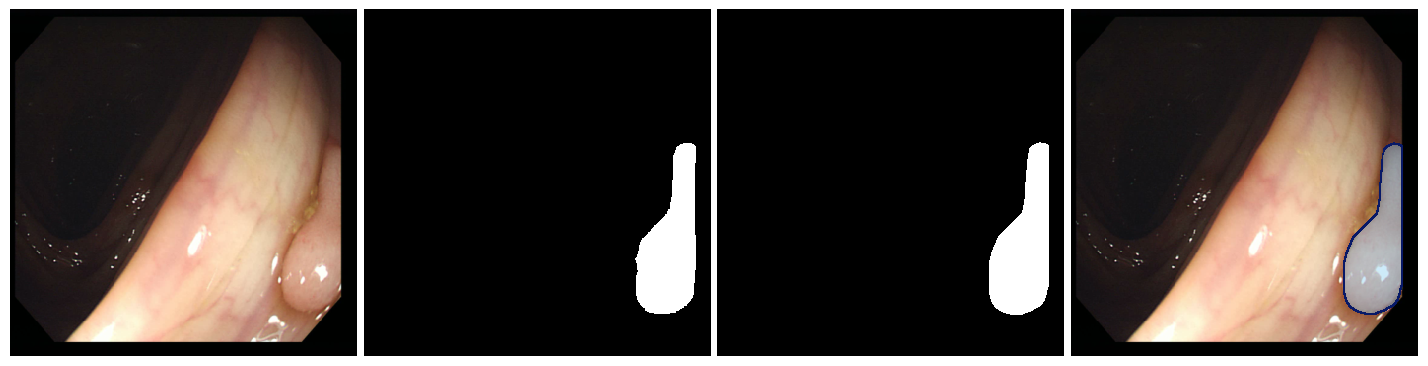

Prediction and export completed.
Prediction foreground pixels: 7023
Ground-truth foreground pixels: 6968
Output directory: /kaggle/working/segmentation_results
Download archive: /kaggle/working/segmentation_results.zip


In [16]:

import os
import zipfile
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.ndimage import binary_erosion, binary_dilation
import torchvision.transforms as T


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.final(d1)


IMAGE_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/images/100.png"
MASK_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/masks/100.png"
CHECKPOINT_PATH = "/kaggle/working/best_unet_ema.pth"
OUTPUT_DIR = "/kaggle/working/segmentation_results"

IMAGE_SIZE = (352, 352)
THRESHOLD = 0.5
FILL_COLOR = np.array([135, 206, 250], dtype=np.float32)
FILL_ALPHA = 0.4
BORDER_COLOR = np.array([8, 25, 103], dtype=np.uint8)
BORDER_WIDTH = 2

os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet(in_channels=3, out_channels=1).to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint)
model.eval()

image_transform = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image = ImageOps.exif_transpose(
    Image.open(IMAGE_PATH)
).convert("RGB")

image_352 = image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.BILINEAR
)
original = np.asarray(image_352).copy()
input_tensor = image_transform(image).unsqueeze(0).to(device)

gt_image = ImageOps.exif_transpose(
    Image.open(MASK_PATH)
).convert("L")

gt_image = gt_image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.NEAREST
)
gt_mask = (np.asarray(gt_image) > 127).astype(np.uint8)

with torch.inference_mode():
    logits = model(input_tensor)
    logits = F.interpolate(
        logits,
        size=IMAGE_SIZE,
        mode="bilinear",
        align_corners=False
    )
    probabilities = torch.sigmoid(logits)[0, 0].cpu().numpy()
    pred_mask = (probabilities >= THRESHOLD).astype(np.uint8)

overlay = original.astype(np.float32).copy()
foreground = pred_mask.astype(bool)

overlay[foreground] = (
    (1.0 - FILL_ALPHA) * overlay[foreground]
    + FILL_ALPHA * FILL_COLOR
)

boundary = foreground & ~binary_erosion(
    foreground,
    structure=np.ones((3, 3), dtype=bool),
    iterations=1,
    border_value=0
)

if BORDER_WIDTH > 1:
    boundary = binary_dilation(
        boundary,
        structure=np.ones((3, 3), dtype=bool),
        iterations=BORDER_WIDTH - 1
    ) & foreground

overlay[boundary] = BORDER_COLOR
overlay = np.clip(overlay, 0, 255).astype(np.uint8)

Image.fromarray(pred_mask * 255).save(
    os.path.join(OUTPUT_DIR, "predicted_mask.png")
)
Image.fromarray(gt_mask * 255).save(
    os.path.join(OUTPUT_DIR, "ground_truth_mask.png")
)
Image.fromarray(overlay).save(
    os.path.join(OUTPUT_DIR, "prediction_overlay.png")
)

panels = [original, gt_mask * 255, pred_mask * 255, overlay]
names = [
    "original",
    "ground_truth",
    "predicted_mask",
    "prediction_overlay"
]

fig, axes = plt.subplots(1, 4, figsize=(14.08, 3.52))

for ax, panel in zip(axes, panels):
    if panel.ndim == 2:
        ax.imshow(
            panel,
            cmap="gray",
            vmin=0,
            vmax=255,
            interpolation="nearest",
            origin="upper"
        )
    else:
        ax.imshow(
            panel,
            interpolation="nearest",
            origin="upper"
        )
    ax.axis("off")

fig.subplots_adjust(
    left=0, right=1, top=1, bottom=0, wspace=0.02
)

fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.png"),
    dpi=300,
    bbox_inches="tight",
    pad_inches=0
)
fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.pdf"),
    dpi=300,
    bbox_inches="tight",
    pad_inches=0
)
plt.show()
plt.close(fig)

for name, panel in zip(names, panels):
    fig_one, ax = plt.subplots(figsize=(3.52, 3.52))

    if panel.ndim == 2:
        ax.imshow(
            panel,
            cmap="gray",
            vmin=0,
            vmax=255,
            interpolation="nearest",
            origin="upper"
        )
    else:
        ax.imshow(
            panel,
            interpolation="nearest",
            origin="upper"
        )

    ax.axis("off")
    fig_one.subplots_adjust(left=0, right=1, top=1, bottom=0)

    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.png"),
        dpi=300,
        bbox_inches="tight",
        pad_inches=0
    )
    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.pdf"),
        dpi=300,
        bbox_inches="tight",
        pad_inches=0
    )
    plt.close(fig_one)

zip_path = "/kaggle/working/segmentation_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in sorted(os.listdir(OUTPUT_DIR)):
        archive.write(
            os.path.join(OUTPUT_DIR, filename),
            arcname=filename
        )

print("Prediction and export completed.")
print(f"Prediction foreground pixels: {pred_mask.sum()}")
print(f"Ground-truth foreground pixels: {gt_mask.sum()}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Download archive: {zip_path}")